In [ ]:
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.datasets import load_wine
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    ConfusionMatrixDisplay
)

In [ ]:
#Load dataset
wine = load_wine()

X = wine.data
y = wine.target

# Keep only classes 0 and 1
mask = y < 2

X = X[mask]
y = y[mask]

print("Dataset shape:", X.shape)
print("Target classes:", wine.target_names[:2])
print("Class distribution:", {i: sum(y == i) for i in range(2)})

Dataset shape: (130, 13)
Target classes: ['class_0' 'class_1']
Class distribution: {0: np.int64(59), 1: np.int64(71)}


In [ ]:
#Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 104
Testing samples: 26


In [ ]:
#Pipeline — standardize features and train KNN model
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(
        n_neighbors=5
    ))
])

knn_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', KNeighborsClassifier())])

In [ ]:
#Predict using KNN
y_pred = knn_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=wine.target_names[:2]
))

Accuracy: 0.9615384615384616
Precision: 1.0
Recall: 0.9285714285714286
F1 score: 0.9629629629629629

Classification Report:
              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       1.00      0.93      0.96        14

    accuracy                           0.96        26
   macro avg       0.96      0.96      0.96        26
weighted avg       0.96      0.96      0.96        26



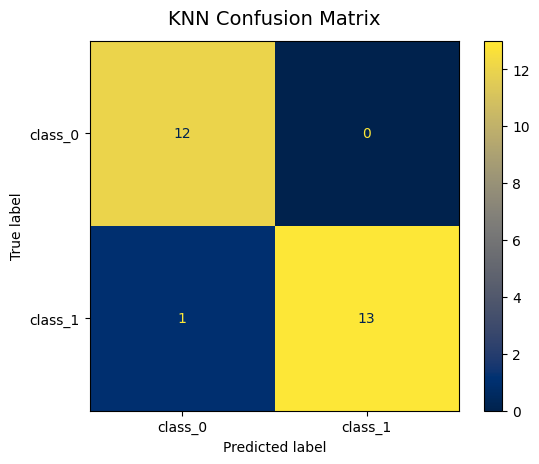

In [ ]:
#Confusion matrix
cm = ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=wine.target_names[:2],
    cmap=plt.cm.cividis
)

plt.title("KNN Confusion Matrix", fontsize=14, pad=12)
plt.show()

In [ ]:
#Probability of positive class
y_prob = knn_model.predict_proba(X_test)[:, 1]

print("Predicted probabilities:")
print(y_prob)

Predicted probabilities:
[0.2 0.  1.  1.  0.4 0.  1.  1.  0.  1.  0.  1.  1.  0.  0.6 0.  0.  0.
 0.  1.  1.  0.6 0.  1.  0.  1. ]


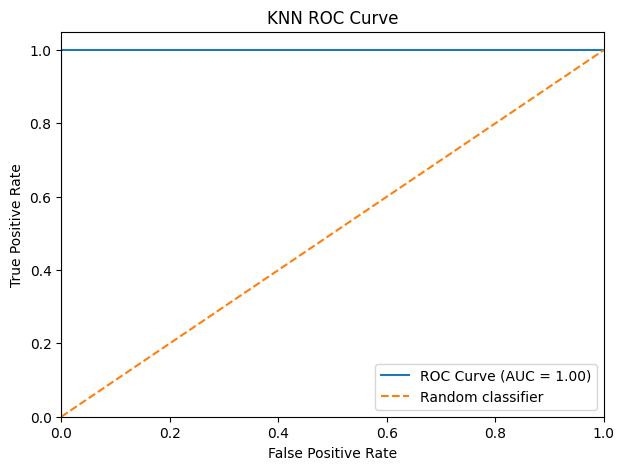

In [ ]:
#Plot ROC curve
fpr, tpr, threshold = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC Curve (AUC = {roc_auc_score(y_test, y_prob):.2f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("KNN ROC Curve")
plt.legend()
plt.show()

In [ ]:
#Calculate area under the curve (AUC)
auc = roc_auc_score(y_test, y_prob)

print("AUC:", auc)

AUC: 1.0


In [ ]:
#KNN cross-validation
knn_score = cross_val_score(
    knn_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Scores:", knn_score)
print("Scores mean:", knn_score.mean())

Scores: [0.9047619  1.         0.95238095 1.         1.        ]
Scores mean: 0.9714285714285713
